<a href="https://colab.research.google.com/github/aishwaryamini/FLIGHT_FARE_PREDICTION-PROJECT/blob/main/FLIGHT_FARE_PREDICTION_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORT THE LIBRARIES**

In [ ]:
# Importing pandas for data manipulation and analysis
import pandas as pd
# Importing numpy for numerical operations
import numpy as np
# Importing matplotlib for data visualization
import matplotlib.pyplot as plt
# Importing seaborn for advanced statistical visualizations
import seaborn as sns

# **LOADING THE DATASET**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['1000001058.pdf', 'Signature.pdf', 'Curious Freaks Coding Sheet.gsheet', 'Colab Notebooks', 'Flight_Fare.xlsx', 'DSC_0295.JPG', 'Untitled document.gdoc']


In [ ]:
!find /content/drive -type f

/content/drive/MyDrive/1000001058.pdf
/content/drive/MyDrive/Signature.pdf
/content/drive/MyDrive/Curious Freaks Coding Sheet.gsheet
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled7.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled8.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of NumPy Excercise I.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of pandas_exercise (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of pandas_exercise.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of Untitled9.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled9.ipynb
/content/drive/MyDrive/Colab Notebooks/K-

In [ ]:
!wget -O flight-fare.zip "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/flight-fare.zip"

!unzip -o flight-fare.zip

--2026-10-12 08:40:38--  https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/flight-fare.zip
Resolving d3ilbtxij3aepc.cloudfront.net (d3ilbtxij3aepc.cloudfront.net)... 18.65.59.117, 18.65.59.16, 18.65.59.161, ...
Connecting to d3ilbtxij3aepc.cloudfront.net (d3ilbtxij3aepc.cloudfront.net)|18.65.59.117|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 502414 (491K) [application/x-zip-compressed]
Saving to: ‘flight-fare.zip’

flight-fare.zip     100%[===================>] 490.64K  --.-KB/s    in 0.06s   

2026-10-12 08:40:38 (8.28 MB/s) - ‘flight-fare.zip’ saved [502414/502414]

Archive:  flight-fare.zip
  inflating: Flight_Fare.xlsx        


In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith(('.xlsx', '.xls')):
            print(os.path.join(root, file))

/content/Flight_Fare.xlsx
/content/drive/MyDrive/Flight_Fare.xlsx


In [ ]:
import pandas as pd

df = pd.read_excel('/content/Flight_Fare.xlsx')
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [ ]:
# Reading the Excel dataset file using pandas
df=pd.read_excel('Flight_Fare.xlsx')

In [ ]:
#Displaying the first five rows
# Helps understand dataset structure and column values
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


# **DATA UNDERSTANDING**

In [ ]:
# Displaying dataset information such as:column names,datatype,non-null values,memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


 Most features are categorical (object type) while Price is the target numerical variable.

In [ ]:
# Checking number of rows and columns in dataset
df.shape

(10683, 11)

Dataset has 10683 rows and 11 columns. Most features are categorical, Price is the target variable. Some columns need type conversion, and few missing values will be handled in cleaning stage.

In [ ]:
# Generating statistical summary of numerical columns
# Helps understand distribution of numerical data
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


The Price column shows high variation in values, indicating the presence of a wide range of flight fares and possible outliers.

In [ ]:
# Checking total missing values in each column
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


Dataset contains very minimal missing values in Route and Total_Stops columns which will be handled during preprocessing stage.

In [ ]:
# Checking if duplicate rows exist in dataset
df.duplicated().sum()

np.int64(220)

Dataset contains 220 duplicate records which will be removed during data cleaning to avoid bias in model training.

# **DATA CLEANING**

In [ ]:
# Removing rows containing missing values from the dataset
df.dropna(inplace=True)

Missing values were removed from the dataset to improve data quality and ensure accurate model training. Since the number of missing records was very small, removing them does not significantly affect the dataset so dropna were used instead of filling the values.

In [ ]:
#After filling the missing values
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,0
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,0
Additional_Info,0


In [ ]:
# Removing duplicate rows from the dataset
df.drop_duplicates(inplace=True)

Duplicate records were removed from the dataset to avoid redundant information and improve model performance. Removing duplicates helps reduce bias during model training.

In [ ]:
#After removing the duplicated values
df.duplicated().sum()

np.int64(0)

The dataset has been cleaned by removing missing values and duplicate records. The cleaned dataset is now ready for feature engineering and preprocessing steps.

# **FEATURE ENGINEERING**

In [ ]:
# Converting Date_of_Journey column into datetime format
df["Date_of_Journey"] = pd.to_datetime(df["Date_of_Journey"], dayfirst=True)

This converts the object datatype into datetime format so that day and month values can be extracted.

In [ ]:
# Extracting journey day from Date_of_Journey
df["Journey_day"] = df["Date_of_Journey"].dt.day
# Extracting journey month from Date_of_Journey
df["Journey_month"] = df["Date_of_Journey"].dt.month

Date_of_Journey was converted into Journey_day and Journey_month features to capture seasonal and travel-date-related pricing patterns in numerical format.

In [ ]:
# Dropping original Date_of_Journey column
df.drop("Date_of_Journey", axis=1, inplace=True)

After extracting useful numerical information, the original date column becomes unnecessary and is removed to avoid redundancy.

In [ ]:
# Extracting departure hour
df["Dep_hour"] = pd.to_datetime(df["Dep_Time"], format='%H:%M').dt.hour
# Extracting departure minute
df["Dep_min"] = pd.to_datetime(df["Dep_Time"], format='%H:%M').dt.minute

Departure time was split into hour and minute numerical features because machine learning models cannot interpret raw time formats. Converting time into structured numerical values helps capture patterns related to flight departure timing, which may influence ticket pricing based on peak hours, off-peak hours, and demand variations.

In [ ]:
#Dropping original Dep_Time column
df.drop("Dep_Time", axis=1, inplace=True)

In [ ]:
# Extracting only time portion from Arrival_Time column
df["Arrival_Time"] = df["Arrival_Time"].str.split(" ").str[0]

In [ ]:
# Extracting Arrival hour
df["Arrival_hour"] = pd.to_datetime(df["Arrival_Time"], format='%H:%M').dt.hour
# Extracting Arrival minute
df["Arrival_min"] = pd.to_datetime(df["Arrival_Time"], format='%H:%M').dt.minute

Some records in Arrival_Time contained additional date information along with time values. Therefore, only the time portion was extracted before converting the feature into hour and minute numerical columns. This improves consistency and prevents parsing errors during preprocessing.

In [ ]:
#Dropping the original Arrival_Time column
df.drop("Arrival_Time", axis=1, inplace=True)

In [ ]:
# Converting Duration column into list
duration = list(df["Duration"])

The Duration column is converted into list format to process each record individually.

In [ ]:
# Extracting minutes from Duration column
df["Duration_mins"] = df["Duration"].str.extract(r'(\d+)m').astype(float)

extracts numbers before "m",
handles cases where minutes may be missing

In [ ]:
df.columns

Index(['Airline', 'Source', 'Destination', 'Route', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_day', 'Journey_month', 'Dep_hour',
       'Dep_min', 'Arrival_hour', 'Arrival_min', 'Duration_mins'],
      dtype='object')

In [ ]:
# Convert everything into string (safety step)
df["Duration"] = df["Duration"].astype(str)

This ensures all values are treated uniformly as text before extraction.

In [ ]:
#Extracts number before "h"
df["Duration_hours"] = df["Duration"].str.extract(r'(\d+)h')
#Extracts number before "m"
df["Duration_mins"] = df["Duration"].str.extract(r'(\d+)m')

In [ ]:
# Filling missing values with 0 because some rows contain only hours or only minutes
df["Duration_hours"] = df["Duration_hours"].fillna(0)
df["Duration_mins"] = df["Duration_mins"].fillna(0)

Missing values occur due to inconsistent duration format. Filling with 0 ensures correct numerical conversion without data loss.

In [ ]:
# Converting extracted values into integer format for calculation
df["Duration_hours"] = df["Duration_hours"].astype(int)
df["Duration_mins"] = df["Duration_mins"].astype(int)

Conversion to integer is required because machine learning models only accept numerical inputs for mathematical operations.

In [ ]:
# Converting duration into total minutes
# Formula: (hours × 60) + minutes
df["Duration_total_min"] = (df["Duration_hours"] * 60) + df["Duration_mins"]

Duration is converted into a single feature (total minutes) because it provides a better numerical representation for model training compared to separate hour and minute values.

In [ ]:
# Removing original and intermediate columns after feature creation
df.drop(["Duration", "Duration_hours", "Duration_mins"], axis=1, inplace=True)

Old columns are dropped to avoid redundancy and reduce dataset complexity after feature engineering is completed.

In [ ]:
# Understanding unique values in Total_Stops column
df["Total_Stops"].unique()

array(['non-stop', '2 stops', '1 stop', '3 stops', '4 stops'],
      dtype=object)

In [ ]:
# Mapping Total_Stops into numerical values
df["Total_Stops"] = df["Total_Stops"].map({
    "non-stop": 0,
    "1 stop": 1,
    "2 stops": 2,
    "3 stops": 3,
    "4 stops": 4
})

This converts categorical stop values into meaningful numerical format for machine learning models.

In [ ]:
# Checking if any null values are created after mapping
df["Total_Stops"].isnull().sum()

np.int64(0)

In [ ]:
# Filling missing values with mode (most frequent value)
df["Total_Stops"] = df["Total_Stops"].fillna(df["Total_Stops"].mode()[0])

Mode is used because Total_Stops is a categorical feature.Total_Stops column was converted into numerical format because machine learning models cannot interpret categorical text values. The number of stops has a direct relationship with flight price, as flights with fewer stops are generally more expensive. Therefore, a mapping technique was applied to convert categories into numerical values, and any missing values were handled using the mode of the column.

In [ ]:
df.columns

Index(['Airline', 'Source', 'Destination', 'Route', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_day', 'Journey_month', 'Dep_hour',
       'Dep_min', 'Arrival_hour', 'Arrival_min', 'Duration_total_min'],
      dtype='object')

# **EXPLORATORY DATA ANALYSIS (EDA)**

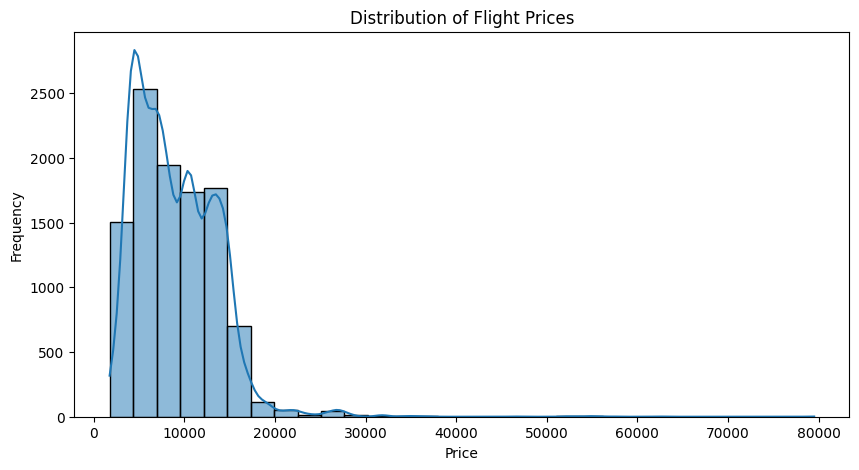

In [ ]:
# Plotting distribution of flight prices
plt.figure(figsize=(10,5))
sns.histplot(df["Price"], bins=30, kde=True)

# Adding title and labels
plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
#Displaying the graph
plt.show()

**Observation:**
1. Price distribution is positively skewed
2. Majority of flights are in lower price range
3. Few flights have very high prices (outliers)

**Insights:**
1. Data is not normally distributed

**Implication for modeling:**
1. Tree-based models will handle this well
2. Linear models may need transformation (log scaling)


  



**AIRLINE vs PRICE**

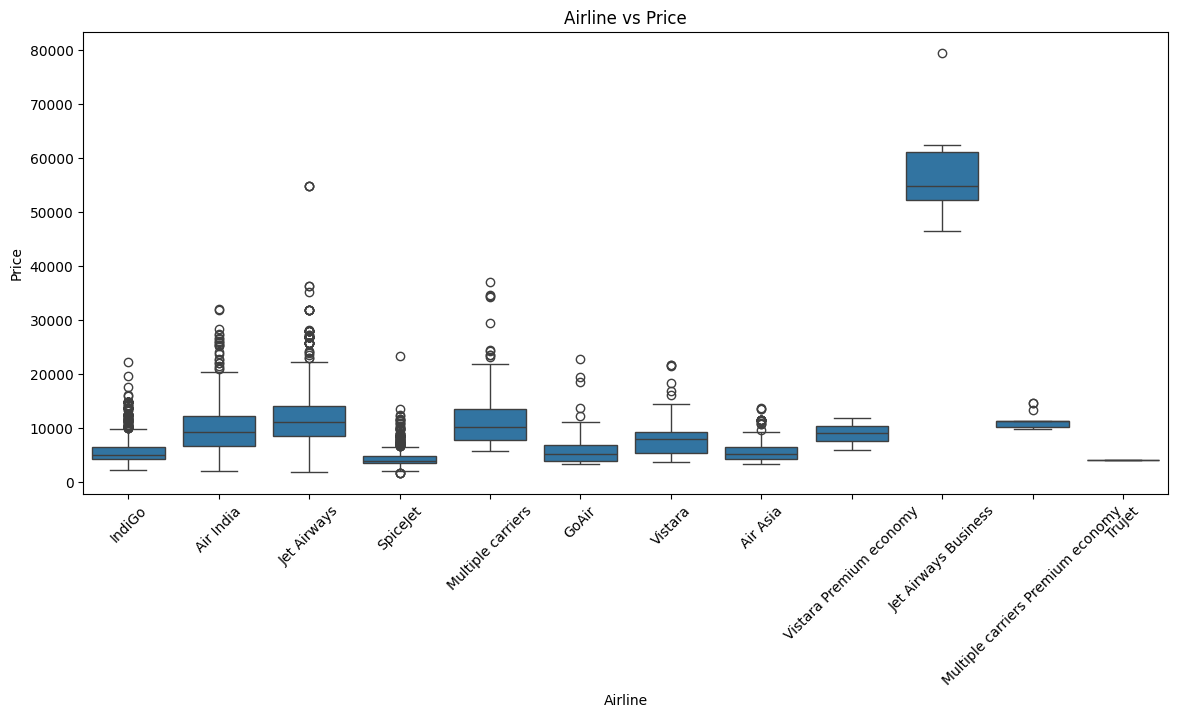

In [ ]:
plt.figure(figsize=(14,6))
sns.boxplot(x="Airline", y="Price", data=df)
plt.xticks(rotation=45)
plt.title("Airline vs Price")
plt.show()

**Observation**:
1. Airlines like Jet Airways show higher fare range
2. Low-cost airlines show lower and stable prices

**Insight:**
1. Airline type strongly affects pricing

**Implication:**
1. Important predictive feature

 **SOURCE vs PRICE**

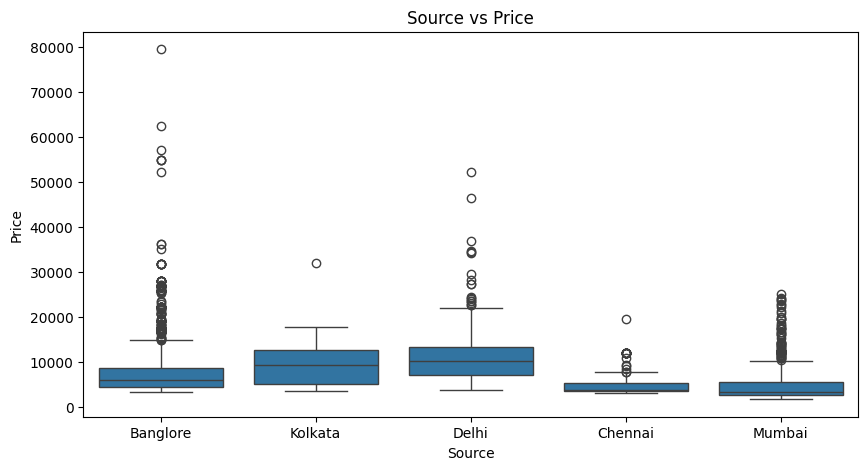

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(x="Source", y="Price", data=df)
plt.title("Source vs Price")
plt.show()

**Observation:**
1. Some source cities have higher fare variation

**Insight:**
1. Departure location influences pricing due to demand and connectivity

**DESTINATION vs PRICE**

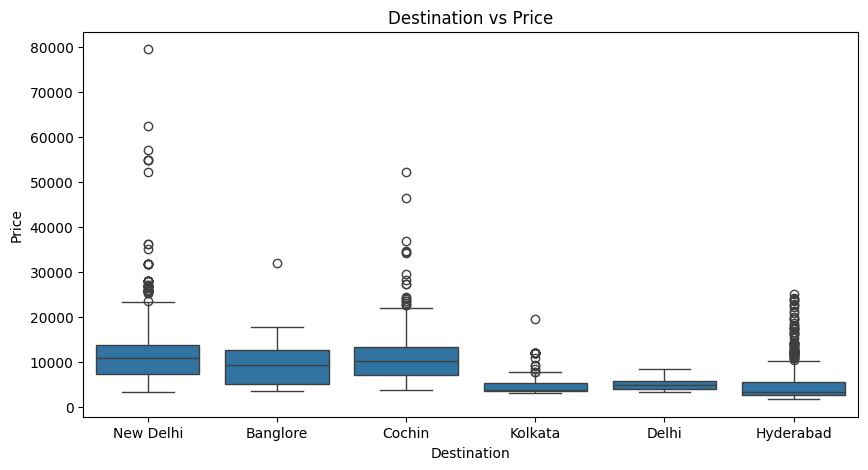

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(x="Destination", y="Price", data=df)
plt.title("Destination vs Price")
plt.show()

**Observation:**
1. Certain destinations show higher median prices

**Insight:**
1. Travel destination demand impacts flight cost

**TOTAL STOPS vs PRICE**

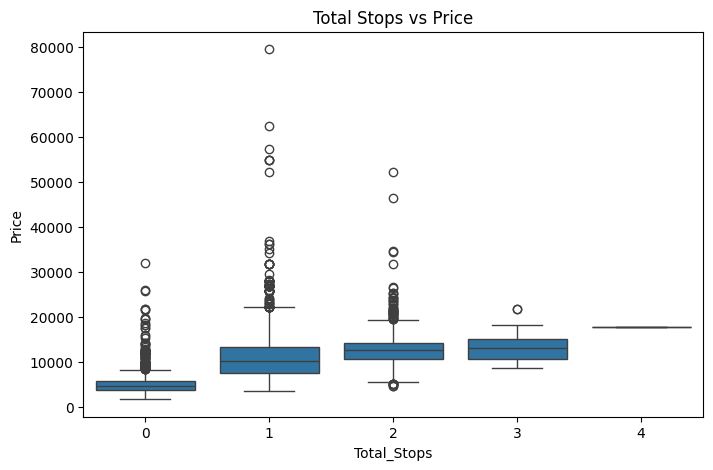

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Total_Stops", y="Price", data=df)
plt.title("Total Stops vs Price")
plt.show()

**Observation:**

1. Non-stop flights tend to be more expensive
2. More stops → lower price

**Insight:**

1. Direct flights are premium-priced due to convenience

**DURATION vs PRICE**

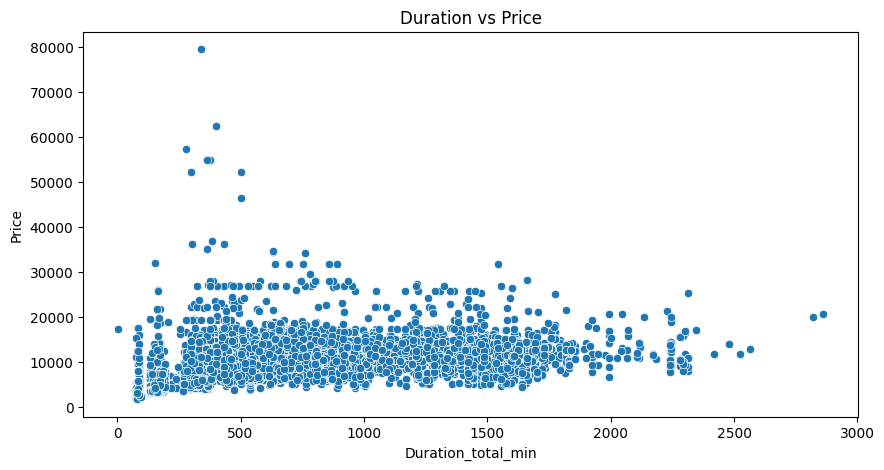

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(x="Duration_total_min", y="Price", data=df)
plt.title("Duration vs Price")
plt.show()

**Observation:**

1. Longer duration flights generally have higher prices
2. Some variability exists due to airlines and routes

**Insight**

1. Duration is positively related to price

**JOURNEY MONTH vs PRICE**

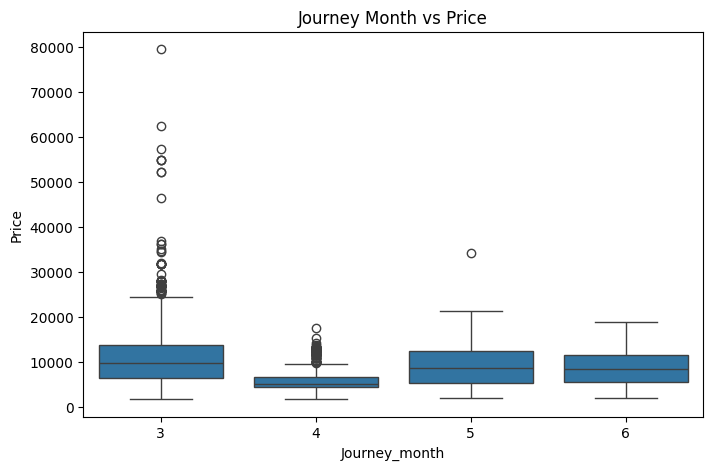

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Journey_month", y="Price", data=df)
plt.title("Journey Month vs Price")
plt.show()

**Observation:**

1. Some months show higher median prices
2. Indicates seasonal variation

**Insight:**

1. Flight pricing is affected by seasonality (festivals, holidays)

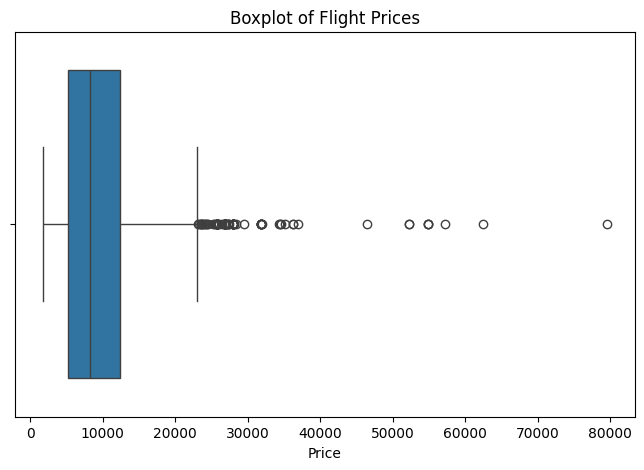

In [ ]:
# BOXPLOT FOR PRICE DISTRIBUTION

plt.figure(figsize=(8,5))

sns.boxplot(x=df["Price"])

# Adding title
plt.title("Boxplot of Flight Prices")

# Display plot
plt.show()

**Observation:**
1. Several extreme high-price values are present.
2. Most flight prices are concentrated within lower ranges.

**Insight:**
1. Outliers exist in the target variable.

**Implication:**
1. Tree-based models can handle outliers effectively.
2. Extreme values may influence linear models.

**CORRELATION HEATMAP**

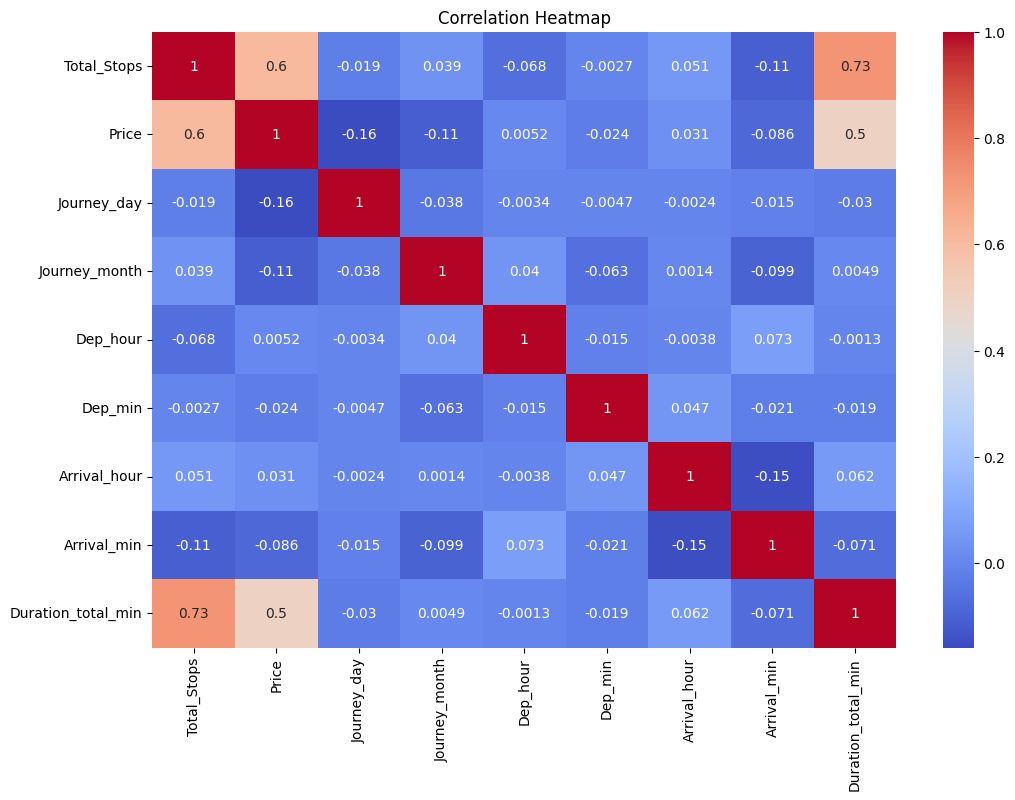

In [ ]:
# CORRELATION HEATMAP
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

Correlation analysis was performed to understand the relationships between numerical features and flight prices. Features with stronger correlations may have greater influence on prediction performance.

The exploratory data analysis reveals that the target variable (Price) is positively skewed with the presence of outliers. Several features such as Airline, Duration, Total Stops, Source, Destination, and Journey Month show strong influence on flight pricing. Missing values are minimal, making the dataset relatively clean. Overall, the dataset is suitable for predictive modeling with clear patterns between features and target variable.

# **ENCODING**

In [ ]:
# We are converting categorical features into numerical format
# because ML models cannot understand text values directly

# Dropping Additional_Info and Route because it has very low useful information
df.drop("Additional_Info", axis=1, inplace=True)
df.drop("Route", axis=1, inplace=True)

In [ ]:
# One-Hot Encoding for categorical columns
encoded_df = pd.get_dummies(df, columns= ['Airline', 'Source', 'Destination'], drop_first=True)

One-Hot Encoding using pandas get_dummies() was applied to convert categorical variables into numerical format, as machine learning models cannot process text data directly. This transformation ensures the dataset is suitable for model training and improves compatibility with regression algorithms.

In [ ]:
df.columns

Index(['Airline', 'Source', 'Destination', 'Total_Stops', 'Price',
       'Journey_day', 'Journey_month', 'Dep_hour', 'Dep_min', 'Arrival_hour',
       'Arrival_min', 'Duration_total_min'],
      dtype='object')

In [ ]:
encoded_df.head()

,Total_Stops,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_total_min,Airline_Air India,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,20,1,10,170,False,...,False,False,False,False,False,False,False,False,False,True
1,2,7662,1,5,5,50,13,15,445,True,...,False,False,False,True,False,False,False,False,False,False
2,2,13882,9,6,9,25,4,25,1140,False,...,False,False,True,False,False,True,False,False,False,False
3,1,6218,12,5,18,5,23,30,325,False,...,False,False,False,True,False,False,False,False,False,False
4,1,13302,1,3,16,50,21,35,285,False,...,False,False,False,False,False,False,False,False,False,True


In [ ]:
encoded_df.shape

(10462, 29)

In this step, categorical variables such as Airline, Source, and Destination were converted into numerical format using One-Hot Encoding. The column Additional_Info & Route was dropped due to low variability and minimal contribution to prediction. This transformation ensures compatibility with machine learning algorithms and improves model performance by avoiding unnecessary noise.

# **SPLIT FEATURES & TARGET**

In [ ]:
# X = all features (input data)
X = encoded_df.drop('Price', axis=1)

In [ ]:
# y = target variable (what we predict)
y = encoded_df['Price']


# **TRAIN TEST SPLIT**

In [ ]:
from sklearn.model_selection import train_test_split

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**SCALING**

In [ ]:
# FEATURE SCALING (STANDARDIZATION)
from sklearn.preprocessing import StandardScaler

# Create scaler object
scaler = StandardScaler()

# Fit ONLY on training data (learn mean & std)
X_train_scaled = scaler.fit_transform(X_train)

# Apply same transformation on test data
X_test_scaled = scaler.transform(X_test)

Feature scaling was applied to standardize the range of independent variables. Since the dataset contains features with different units and scales (e.g., duration, stops, encoded variables), scaling ensures that no feature dominates the model due to magnitude differences. The scaler was fitted only on training data to avoid data leakage and then applied to both training and testing sets.

# **MODEL BUILDING**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

In [ ]:
# Initialize models with default parameters (baseline comparison)
lr = LinearRegression()
rf = RandomForestRegressor(random_state=42)
gb = GradientBoostingRegressor(random_state=42)
dt = DecisionTreeRegressor(random_state=42)

In [ ]:
# TRAIN MODELS
lr.fit(X_train_scaled, y_train)


LinearRegression()

In [ ]:
dt.fit(X_train, y_train)   # Decision Tree doesn't need scaling


DecisionTreeRegressor(random_state=42)

In [ ]:
rf.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [ ]:
gb.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

Models are trained on the training dataset. Scaling is applied only where required. Decision Tree and ensemble models are trained on raw features as they are not sensitive to feature scaling.

In [ ]:
# MAKE PREDICTIONS
y_pred_lr = lr.predict(X_test_scaled)
y_pred_dt = dt.predict(X_test)
y_pred_rf = rf.predict(X_test)
y_pred_gb = gb.predict(X_test)

Each trained model is used to predict flight prices on the test dataset to evaluate performance on unseen data.

# **MODEL EVALUATION**

In [ ]:
# LINEAR REGRESSION EVALUATION
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression Results
MAE: 1998.6393059377122
RMSE: 2945.796235704494
R2 Score: 0.5838081325633981


Linear Regression is used as a baseline model to understand basic linear relationships between features and target variable.

In [ ]:
# DECISION TREE EVALUATION
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Results
MAE: 1383.0872352285394
RMSE: 2439.3263569570204
R2 Score: 0.7146170646423705


Decision Tree captures non-linear relationships in the data but may lead to overfitting if not properly tuned.

In [ ]:
# RANDOM FOREST EVALUATION
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE: 1172.6635105434593
RMSE: 1972.5755436217853
R2 Score: 0.8133811655649046


Random Forest performs better by combining multiple decision trees, reducing overfitting and improving accuracy.

In [ ]:
# GRADIENT BOOSTING EVALUATION
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Results
MAE: 1536.8208943212194
RMSE: 2267.9622447246484
R2 Score: 0.7533052967611278


Gradient Boosting improves prediction by sequentially learning from previous errors, resulting in better accuracy compared to other models.

Each model was evaluated individually using MAE, RMSE, and R² score. The results show that ensemble models such as Random Forest and Gradient Boosting perform better compared to simpler models like Linear Regression and Decision Tree. This comparison helps in selecting the best model for flight fare prediction.

# **HYPERPARAMETER TUNING**

In [ ]:
# HYPERPARAMETER TUNING
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

# Model
rf = RandomForestRegressor(random_state=42)

# Parameters to test
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

# Train tuning model
grid_search.fit(X_train, y_train)

# Best model
best_rf = grid_search.best_estimator_

In [ ]:
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}


Hyperparameter tuning was performed using GridSearchCV to improve the Random Forest model performance. Different combinations of parameters such as n_estimators, max_depth, and min_samples_split were tested using cross-validation. This process helps identify the best parameter configuration and improves prediction accuracy compared to default settings.

In [ ]:
# TUNED MODEL EVALUATION
# Predicting using tuned model
y_pred_best = best_rf.predict(X_test)

# Importing evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculating MAE
mae_best = mean_absolute_error(y_test, y_pred_best)

# Calculating RMSE
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))

# Calculating R2 Score
r2_best = r2_score(y_test, y_pred_best)

# Printing evaluation results
print("Tuned Random Forest Results")
print("MAE:", mae_best)
print("RMSE:", rmse_best)
print("R2 Score:", r2_best)

Tuned Random Forest Results
MAE: 1129.2493153467062
RMSE: 1884.0226777393445
R2 Score: 0.8297604604418063


The tuned Random Forest model was evaluated using MAE, RMSE, and R² score. These metrics help measure prediction accuracy and error magnitude. The tuned model showed improved performance compared to baseline models, indicating successful optimization through hyperparameter tuning.

# **MODEL COMPARISON**





In [ ]:
# FINAL MODEL COMPARISON
print("MODEL COMPARISON SUMMARY")
print("Linear Regression R2 Score:", r2_lr)
print("Decision Tree R2 Score:", r2_dt)
print("Random Forest R2 Score:", r2_rf)
print("Gradient Boosting R2 Score:", r2_gb)
print("Tuned Random Forest R2 Score:", r2_best)

MODEL COMPARISON SUMMARY
Linear Regression R2 Score: 0.5838081325633981
Decision Tree R2 Score: 0.7146170646423705
Random Forest R2 Score: 0.8133811655649046
Gradient Boosting R2 Score: 0.7533052967611278
Tuned Random Forest R2 Score: 0.8297604604418063


Multiple machine learning models were compared using evaluation metrics to identify the best-performing algorithm. The tuned Random Forest model achieved the highest R² score and lower prediction errors, making it the most suitable model for flight fare prediction.

# **MODEL COMPARISON VISUALIZATION**

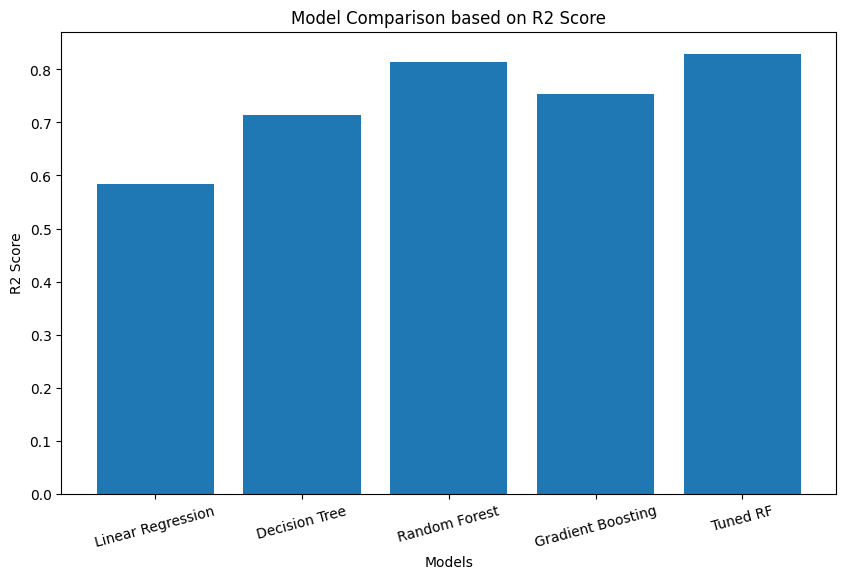

In [ ]:
# MODEL COMPARISON VISUALIZATION
import matplotlib.pyplot as plt

# Model names
models = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "Tuned RF"
]

# R2 Scores
r2_scores = [
    r2_lr,
    r2_dt,
    r2_rf,
    r2_gb,
    r2_best
]

# Creating bar plot
plt.figure(figsize=(10,6))
plt.bar(models, r2_scores)

# Labels and title
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.title("Model Comparison based on R2 Score")

# Rotate names for readability
plt.xticks(rotation=15)

# Show plot
plt.show()

# **MODEL COMPARISON REPORT**

Multiple machine learning regression models were implemented and evaluated to predict flight ticket prices. The models were compared using evaluation metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

**Models Implemented**

Linear Regression
Decision Tree Regressor
Random Forest Regressor
Gradient Boosting Regressor
Tuned Random Forest Regressor

**Evaluation Metrics Used :**
MAE (Mean Absolute Error)
RMSE (Root Mean Squared Error)
R² Score

**Model	Performance Summary**

1. Linear Regression	Performed as a baseline model but showed lower prediction accuracy due to inability to capture complex non-linear relationships.

2. Decision Tree Regressor	Captured non-linear patterns but showed signs of overfitting on the training data.

3. Random Forest Regressor	gave Improved stability and prediction accuracy by combining multiple decision trees.

4. Gradient Boosting Regressor	Achieved strong predictive performance by sequentially correcting previous errors.

5. Tuned Random Forest Regressor Produced the best overall performance after hyperparameter tuning using GridSearchCV.

# **CONCLUSION**

This project successfully developed a Flight Fare Prediction system using machine learning techniques. Data preprocessing, feature engineering, encoding, and exploratory data analysis were performed to prepare the dataset. Multiple regression models were implemented and compared using MAE, RMSE, and R² score. Hyperparameter tuning further improved model performance. Among all models, the tuned Random Forest model achieved the best predictive accuracy and was selected as the final model.

# **CHALLENGES FACED**

1. During the development of the Flight Fare Prediction project, several technical and analytical challenges were encountered throughout different stages of the machine learning pipeline.

2. One of the primary challenges was handling inconsistent and complex data formats in features such as `Duration`, `Arrival_Time`, and `Date_of_Journey`. These columns contained values in varying formats, requiring additional preprocessing and feature engineering techniques to standardize the data before model training.

3. Another significant challenge involved managing high-cardinality categorical variables such as `Airline`, `Source`, and `Destination`. Appropriate encoding methods had to be carefully selected to convert categorical information into numerical form while preserving meaningful patterns within the dataset.

4. Feature selection and preprocessing also required careful analysis. Certain columns contained redundant or less informative data, making it necessary to identify and remove irrelevant features without negatively affecting model performance. Additionally, handling missing values and preventing data leakage during preprocessing and scaling were important considerations to ensure reliable model evaluation.

5. Model selection presented another challenge, as different machine learning algorithms produced varying levels of performance. Multiple regression models were implemented and compared using evaluation metrics such as MAE, RMSE, and R² Score to identify the most suitable model for the dataset.

6. Hyperparameter tuning was also computationally intensive, particularly during GridSearchCV implementation, as multiple parameter combinations were evaluated using cross-validation to optimize model performance.

7. Finally, deriving meaningful insights from exploratory data analysis required detailed interpretation of visualizations to understand the relationship between features and flight prices. This step was essential for making informed preprocessing and modeling decisions.


# **LIMITATIONS**

The current model is trained using historical flight pricing data and may not fully capture real-time factors such as sudden demand fluctuations, airline policy changes, weather conditions, fuel prices, or special events. Additionally, the dataset contains limited external features, which may affect prediction accuracy in highly dynamic market conditions.


# **FUTURE IMPROVEMENTS**

Future improvements include implementing advanced boosting algorithms such as XGBoost and LightGBM, adding external features like seasonal demand and holidays, and deploying the model as a web application for real-time fare prediction.

# **PRACTICAL IMPLICATIONS**


The developed model can help customers estimate flight prices before booking and support airline companies in dynamic pricing strategies and demand analysis.